# LRB-D with the two-ancilla layout: SI1000 and SD6, qutrit and qubit

This notebook plots the four production LRB-D runs of the two-ancilla layout (internal name layout B; `folded_qutrit_layout_b`, `folded_qubit_layout_b`), which replaces the conventional-site two-ancilla layout in the paper (user decision, 2026-11-17). It is the counterpart of `notebooks/06-conventional-site-two-ancilla-si1000-sd6.ipynb`.

**Layout.** Seven qudits on a square lattice, rows `q4 N` / `q1 q2 E` / `q0 q3`, with the eight lattice-adjacent pairs as couplers (`q0-q1, q0-q3, q1-q2, q2-q3, q1-q4, N-q4, N-q2, E-q2`). The encoder (four CNOTs on `q0-q1, q0-q3, q1-q2, q1-q4`) and the logical gates (`q2-q3`) are nearest-neighbour.

- Ancilla N measures $G_2$ and then $G_4$; ancilla E measures $G_1$ and then $G_3$. Neither neighbours three data qudits of a stabilizer, so each check moves parity through data CNOTs on `q0-q1, q1-q2, q1-q4, q2-q3` and undoes them before the readout; `q0-q3` is encoder-only because $X_0X_3$ is logical.
- Each ancilla is read twice per round (readouts N, E, N, E) and reset once, at the start of the round; a nonzero first readout already rejects the shot, so the pass rule (all readouts zero) is unchanged.
- 24 two-qudit gates and 4 one-qudit gates per round, 19 gate moments plus one reset and two readout moments under the ASAP scheduler; no undetected logical error from any single fault (qutrit and qubit).

Same circuit-level noise, mirror inverse, grids, fit settings and threshold estimator as the other sdim 1.4.0 runs.


### 0. Environment check

The kernel should be the repo venv (`.venv-sdim140`), which pins sdim 1.4.0.

In [1]:
from importlib.metadata import version
version("sdim")

'1.4.0'

### 1. Shared imports and configuration

Same fit, threshold, GIF and paper settings as the earlier DEM notebooks, except the axis is the two-qudit gate error $p$ (`p_axis_scale=1.0`).

In [2]:
from pathlib import Path
import sys
import importlib

import pandas as pd
from IPython.display import Image, display


def find_repo_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "src" / "lrb" / "lrb_plotting.py").exists():
            return candidate
    raise FileNotFoundError("Could not locate repository root containing src/lrb/lrb_plotting.py")


REPO_ROOT = find_repo_root(Path.cwd())
SRC_PATH = REPO_ROOT / "src"
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

import lrb.lrb_plotting as _lrb_plotting
import lrb.lrb_gif_plotting as _lrb_gif_plotting

# Ensure notebook uses latest local edits to plotting/GIF modules.
importlib.reload(_lrb_plotting)
importlib.reload(_lrb_gif_plotting)

from lrb.lrb_plotting import (
    LRBPlotFitConfig,
    LRBResultsPlotter,
    LRBThresholdConfig,
    LRBPaperPlotConfig,
)
from lrb.lrb_gif_plotting import LRBGifAnimator, LRBGifRenderConfig


def resolve_working_folder(
    code_name: str,
    lrb_root=None,
) -> str:
    root = Path(lrb_root) if lrb_root is not None else REPO_ROOT / "LRB-experiment-data-slurm"
    code_marker = root / f"working-folder-{code_name}.txt"
    legacy_marker = root / "working-folder.txt"

    def marker_path(marker: Path):
        if not marker.exists():
            return None
        run_name = marker.read_text(encoding="utf-8").strip()
        if not run_name:
            return None
        run_path = root / run_name
        if not run_path.exists():
            return None
        return str(run_path) + "/"

    for marker in (code_marker, legacy_marker):
        maybe_path = marker_path(marker)
        if maybe_path is not None:
            return maybe_path

    candidates = sorted(
        root.glob(f"Run-*-{code_name}*"),
        key=lambda p: p.stat().st_mtime,
        reverse=True,
    )
    if candidates:
        return str(candidates[0]) + "/"

    raise FileNotFoundError(
        f"No run folder found for code '{code_name}' under {root.resolve()}"
    )


fit_config = LRBPlotFitConfig(
    a_fixed=0.0,
    y_ceiling=1.0,
    min_fit_points_lrb=2,
    min_fit_points_rb=3,
    f_min=1e-8,
    f_max=1.0000000,
    rb_a_fixed=0.0,
    # SI1000 and SD6 are parameterized by the two-qudit gate depolarizing
    # probability p (Gidney et al. 2021); plot against it directly.
    p_axis_scale=1.0,
    p_axis_label="Two-qudit gate error rate $p$",
    p_axis_symbol="p",
    p_axis_column=None,
)

threshold_config = LRBThresholdConfig(
    tol=5e-4,
    require_consecutive=2,
    ignore_first_n=3,
    err_floor=2e-3,
    tail_min_prefix=6,
    tail_drop_tol_abs=0.01,
    tail_drop_tol_rel=0.25,
    p_min=None,
    p_max=None,
    min_lrb_n_points_keep=0,
    min_rb_n_points_keep=0,
    zoom_half_window_points=4,
    zoom_pad_frac=0.25,
    min_zoom_span=0.01,
    p_window_before_points=8,
    p_window_after_points=5,
    min_points_in_view=6,
    view_pad_frac=0.15,
    bootstrap_reps_error=500,
    bootstrap_reps_threshold=1000,
    bootstrap_ci_level=0.68,
    bootstrap_use_sem=True,
    bootstrap_seed=12345,
    paper_mode=True,
    paper_cols=2,
    paper_panel_width_in=3.2,
    paper_panel_height_in=2.5,
)

# Shared check ranges for all multi-check plotting/table methods.
const_check_min = 0
const_check_max = 0
unif_check_min = 1
unif_check_max = 22

# Optional pseudo-threshold fit controls.
pseudo_do_fit = False
pseudo_fit_model = "exp"  # or "poly"
pseudo_fit_degree = 1


gif_render_config = LRBGifRenderConfig(
    fps=10,
    dpi=120,
    hold_frames=1,
    transition_frames=6,
)

paper_plot_config = LRBPaperPlotConfig(
    enabled=True,
    column_layout="double",
    rows_per_page=3,
    pairs_per_row=2,
    num_prob_samples=6,
    # Circuit-level range on the production grid:
    # p = 1e-4, 5e-4, 1e-3, 2e-3, 5e-3, 1e-2.
    prob_sample_indices=(1, 3, 4, 5, 6, 8),
    row_height_in=1.6,
    panel_title_fontsize=7.0,
    axis_label_fontsize=6.6,
    tick_fontsize=6.0,
    legend_fontsize=5.7,
    line_width=0.85,
    marker_size=2.6,
    errorbar_capsize=1.2,
    show_legend_first_row_only=False,
    compact_fit_legend=True,
    legend_on_rejected_panel=True,
)

def show_error_rate_uncertainty_table(table_csv: str, label: str) -> pd.DataFrame:
    frame = pd.read_csv(table_csv)
    coordinate_columns = [
        c for c in ("lrb_lambda", "rb_p", "lambda", "p_raw", "p")
        if c in frame.columns
    ]
    sort_column = "lrb_lambda" if "lrb_lambda" in frame.columns else coordinate_columns[0]
    needed = [
        "check_num",
        *coordinate_columns,
        "lrb_error_rate",
        "lrb_error_rate_ci_low",
        "lrb_error_rate_ci_high",
        "rb_error_rate",
        "rb_error_rate_ci_low",
        "rb_error_rate_ci_high",
    ]
    missing = [c for c in needed if c not in frame.columns]
    if missing:
        raise ValueError(
            f"Missing uncertainty columns in {table_csv}: {missing}. "
            "Re-run the table generation cell."
        )

    view = frame[needed].copy()
    view["lrb_unc_minus"] = view["lrb_error_rate"] - view["lrb_error_rate_ci_low"]
    view["lrb_unc_plus"] = view["lrb_error_rate_ci_high"] - view["lrb_error_rate"]
    view["rb_unc_minus"] = view["rb_error_rate"] - view["rb_error_rate_ci_low"]
    view["rb_unc_plus"] = view["rb_error_rate_ci_high"] - view["rb_error_rate"]
    view = view.sort_values(["check_num", sort_column]).reset_index(drop=True)

    print(f"[{label}] error-rate uncertainty table")
    display(view)
    return view

def show_pseudo_threshold_uncertainty_table(
    summary_csv: str,
    label: str,
    check_min=None,
    check_max=None,
) -> pd.DataFrame:
    frame = pd.read_csv(summary_csv)
    threshold_column = (
        "threshold_lrb_lambda"
        if "threshold_lrb_lambda" in frame.columns
        else "threshold_lambda"
        if "threshold_lambda" in frame.columns
        else "threshold_p"
    )
    threshold_std_column = f"{threshold_column}_std_boot"
    threshold_ci_low_column = f"{threshold_column}_ci_low"
    threshold_ci_high_column = f"{threshold_column}_ci_high"
    needed = ["check_num", threshold_column]
    missing = [c for c in needed if c not in frame.columns]
    if missing:
        raise ValueError(
            f"Missing pseudo-threshold columns in {summary_csv}: {missing}. "
            "Re-run threshold generation first."
        )

    view = frame.copy()
    if check_min is not None:
        view = view[view["check_num"] >= int(check_min)]
    if check_max is not None:
        view = view[view["check_num"] <= int(check_max)]
    view = view[view[threshold_column].notna()].copy()

    keep = ["check_num", threshold_column]
    has_std = threshold_std_column in view.columns
    has_ci = (
        threshold_ci_low_column in view.columns
        and threshold_ci_high_column in view.columns
    )
    if has_std:
        keep.append(threshold_std_column)
    if has_ci:
        keep.extend([threshold_ci_low_column, threshold_ci_high_column])

    table = view[keep].copy()
    if has_ci:
        table["threshold_unc_minus"] = (
            table[threshold_column] - table[threshold_ci_low_column]
        )
        table["threshold_unc_plus"] = (
            table[threshold_ci_high_column] - table[threshold_column]
        )
    elif has_std:
        table["threshold_unc_minus"] = table[threshold_std_column]
        table["threshold_unc_plus"] = table[threshold_std_column]
    else:
        raise ValueError(
            f"No pseudo-threshold uncertainty columns found in {summary_csv}."
        )

    table = table.sort_values(["check_num"]).reset_index(drop=True)
    print(f"[{label}] pseudo-threshold uncertainty table")
    display(table)
    return table

### 2. Run selection and output audit

Runs are named explicitly so the notebook does not depend on the mutable `working-folder-*.txt` pointers. The audit requires every LRB and RB CSV before plotting.

In [3]:
RUNS_ROOT = REPO_ROOT / "LRB-experiment-data-slurm"
RUN_NAMES = {
    "layoutb_qutrit_si1000": "Run-2026-11-17-14-38-05-folded_qutrit_layout_b-layout-b-si1000-sdim140",
    "layoutb_qutrit_sd6": "Run-2026-11-17-14-39-18-folded_qutrit_layout_b-layout-b-sd6-sdim140",
    "layoutb_qubit_si1000": "Run-2026-11-17-14-40-29-folded_qubit_layout_b-layout-b-si1000-sdim140",
    "layoutb_qubit_sd6": "Run-2026-11-17-14-41-29-folded_qubit_layout_b-layout-b-sd6-sdim140",
}
EXPECTED_METADATA = {
    "layoutb_qutrit_si1000": ("folded_qutrit_layout_b", "si1000"),
    "layoutb_qutrit_sd6": ("folded_qutrit_layout_b", "sd6"),
    "layoutb_qubit_si1000": ("folded_qubit_layout_b", "si1000"),
    "layoutb_qubit_sd6": ("folded_qubit_layout_b", "sd6"),
}


def read_int_list(path: Path) -> list[int]:
    return [int(v) for v in path.read_text().replace(",", " ").split()]


def read_float_list(path: Path) -> list[float]:
    return [float(v) for v in path.read_text().replace(",", " ").split()]


def audit_run(label: str, run_path: Path) -> pd.DataFrame:
    code_name = (run_path / "code_name.txt").read_text().strip()
    noise_model = (run_path / "noise_model.txt").read_text().strip()
    if (code_name, noise_model) != EXPECTED_METADATA[label]:
        raise ValueError(f"{label}: found {(code_name, noise_model)}, expected {EXPECTED_METADATA[label]}")
    probs = read_float_list(run_path / "probs.txt")
    const_checks = read_int_list(run_path / "check_const.txt")
    unif_checks = read_int_list(run_path / "check_unif.txt")
    rows = []
    for idx, prob in enumerate(probs):
        lrb_path = run_path / "results" / "LRB" / str(idx)
        done_path = run_path / "progress" / str(idx) / "done.txt"
        rows.append({
            "run": label,
            "p_index": idx,
            "p": prob,
            "done_flag": done_path.read_text().strip() if done_path.exists() else "missing",
            "const_csvs": len(list((lrb_path / "const_check_data").glob("*.csv"))),
            "expected_const_csvs": len(const_checks),
            "unif_csvs": len(list((lrb_path / "unif_check_data").glob("*.csv"))),
            "expected_unif_csvs": len(unif_checks),
            "rb_csv_present": (run_path / "results" / "RB" / f"{idx}.csv").exists(),
        })
    return pd.DataFrame(rows)


run_paths = {label: RUNS_ROOT / name for label, name in RUN_NAMES.items()}
audit = pd.concat([audit_run(label, path) for label, path in run_paths.items()], ignore_index=True)
summary = audit.groupby("run").agg(
    indices=("p_index", "count"),
    done=("done_flag", lambda s: int((s == "1").sum())),
    lrb_csvs=("const_csvs", "sum"),
    unif_csvs=("unif_csvs", "sum"),
    expected_const=("expected_const_csvs", "sum"),
    expected_unif=("expected_unif_csvs", "sum"),
    rb_csvs=("rb_csv_present", "sum"),
)
display(summary)
incomplete = audit[
    (audit["done_flag"] != "1")
    | (audit["const_csvs"] != audit["expected_const_csvs"])
    | (audit["unif_csvs"] != audit["expected_unif_csvs"])
    | (~audit["rb_csv_present"])
]
if not incomplete.empty:
    raise ValueError("Incomplete runs/indices:\n" + incomplete.to_string())

,indices,done,lrb_csvs,unif_csvs,expected_const,expected_unif,rb_csvs
run,,,,,,,
layoutb_qubit_sd6,15,15,345,330,345,330,15
layoutb_qubit_si1000,15,15,345,330,345,330,15
layoutb_qutrit_sd6,15,15,345,330,345,330,15
layoutb_qutrit_si1000,15,15,345,330,345,330,15


### 3. Build plotters

One `LRBResultsPlotter` per run. With `p_axis_scale=1.0` and no `rb_comparison_probs.txt`, each plotter pairs LRB at $p$ with physical RB at the same $p$ from `results/RB`.

In [4]:
plotters = {
    label: LRBResultsPlotter(working_folder=str(path) + "/", fit_config=fit_config)
    for label, path in run_paths.items()
}
for label, plotter in plotters.items():
    rb_source, rb_probabilities = plotter._rb_table_source()
    print(f"{label}: {plotter.code_title}")
    print(f"  p grid: {plotter.probabilities}")
    print(f"  RB source: {rb_source}")
    if max(abs(a - b) for a, b in zip(plotter.probabilities, rb_probabilities)) > 0:
        raise ValueError(f"{label}: RB grid is not the LRB p grid.")

layoutb_qutrit_si1000: $[[5,1,2]]_3$ two-ancilla layout, SI1000
  p grid: [0.0, 0.0001, 0.0002, 0.0005, 0.001, 0.002, 0.005, 0.0075, 0.01, 0.0125, 0.015, 0.02, 0.03, 0.04, 0.05]
  RB source: /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-38-05-folded_qutrit_layout_b-layout-b-si1000-sdim140/results/RB
layoutb_qutrit_sd6: $[[5,1,2]]_3$ two-ancilla layout, SD6
  p grid: [0.0, 0.0001, 0.0002, 0.0005, 0.001, 0.002, 0.005, 0.0075, 0.01, 0.0125, 0.015, 0.02, 0.03, 0.04, 0.05]
  RB source: /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-39-18-folded_qutrit_layout_b-layout-b-sd6-sdim140/results/RB
layoutb_qubit_si1000: $[[5,1,2]]_2$ two-ancilla layout, SI1000
  p grid: [0.0, 0.0001, 0.0002, 0.0005, 0.001, 0.002, 0.005, 0.0075, 0.01, 0.0125, 0.015, 0.02, 0.03, 0.04, 0.05]
  RB source: /pscratch/sd/s/sohan100/worktrees/LRB-Simul

### 4. Constant-check plots

`const_check=0` (the direct terminal-X check) for every run, as in the earlier notebooks.

=== layoutb_qutrit_si1000


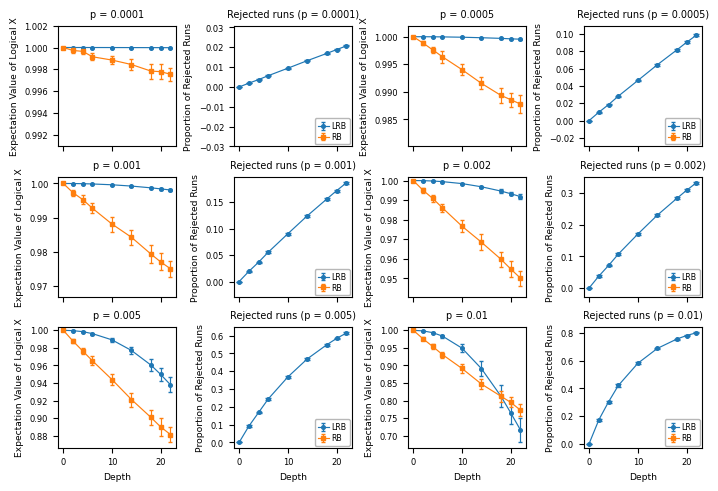

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-38-05-folded_qutrit_layout_b-layout-b-si1000-sdim140/results/plots/const-0-Summary-Graph-NoFit.pdf
=== layoutb_qutrit_sd6


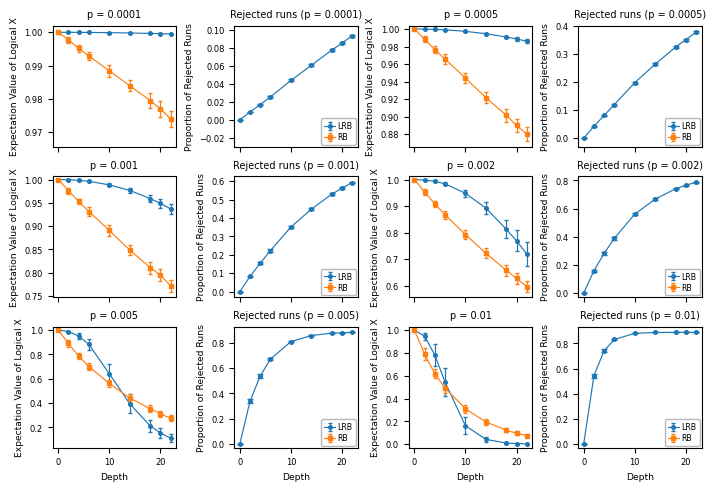

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-39-18-folded_qutrit_layout_b-layout-b-sd6-sdim140/results/plots/const-0-Summary-Graph-NoFit.pdf
=== layoutb_qubit_si1000


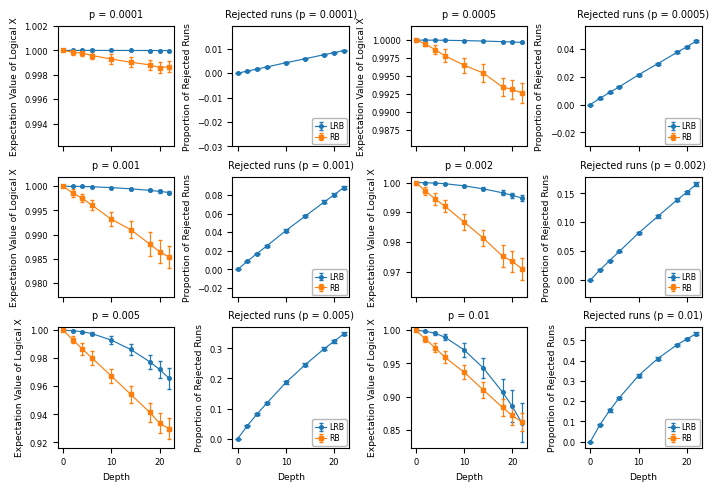

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-40-29-folded_qubit_layout_b-layout-b-si1000-sdim140/results/plots/const-0-Summary-Graph-NoFit.pdf
=== layoutb_qubit_sd6


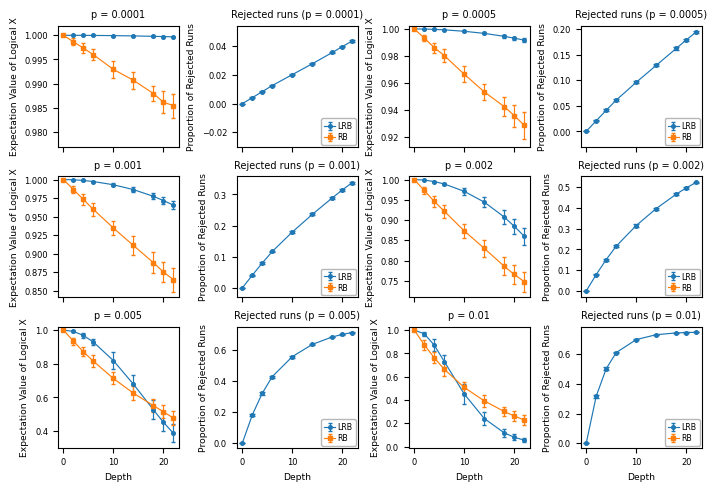

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-41-29-folded_qubit_layout_b-layout-b-sd6-sdim140/results/plots/const-0-Summary-Graph-NoFit.pdf


{'layoutb_qutrit_si1000': ['/pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-38-05-folded_qutrit_layout_b-layout-b-si1000-sdim140/results/plots/const-0-Summary-Graph-NoFit.pdf'],
 'layoutb_qutrit_sd6': ['/pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-39-18-folded_qutrit_layout_b-layout-b-sd6-sdim140/results/plots/const-0-Summary-Graph-NoFit.pdf'],
 'layoutb_qubit_si1000': ['/pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-40-29-folded_qubit_layout_b-layout-b-si1000-sdim140/results/plots/const-0-Summary-Graph-NoFit.pdf'],
 'layoutb_qubit_sd6': ['/pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-41-29-folded_qubit_layout_b-layout-b-sd6-sdim140/results/plots

In [5]:
const_outputs = {}
for label, plotter in plotters.items():
    print(f"=== {label}")
    const_outputs[label] = plotter.plot_all_const_checks(
        show=True,
        check_min=0,
        check_max=0,
        paper_config=paper_plot_config,
    )
const_outputs

### 5. Uniform-check plots

Interval checks `1..4` for every run; raise `unif_plot_max` to `unif_check_max` for all intervals.

=== layoutb_qutrit_si1000


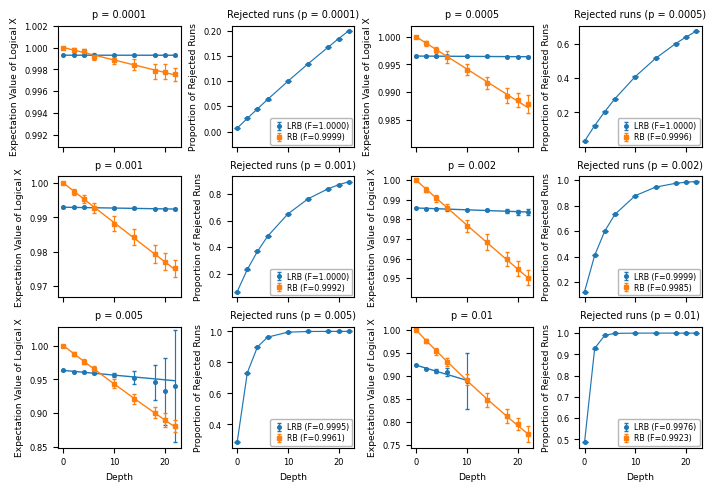

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-38-05-folded_qutrit_layout_b-layout-b-si1000-sdim140/results/plots/unif-1-Summary-Graph-Fit.pdf


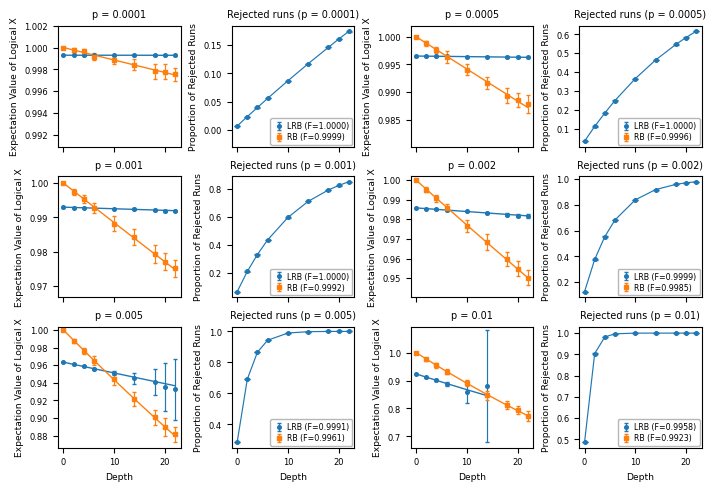

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-38-05-folded_qutrit_layout_b-layout-b-si1000-sdim140/results/plots/unif-2-Summary-Graph-Fit.pdf


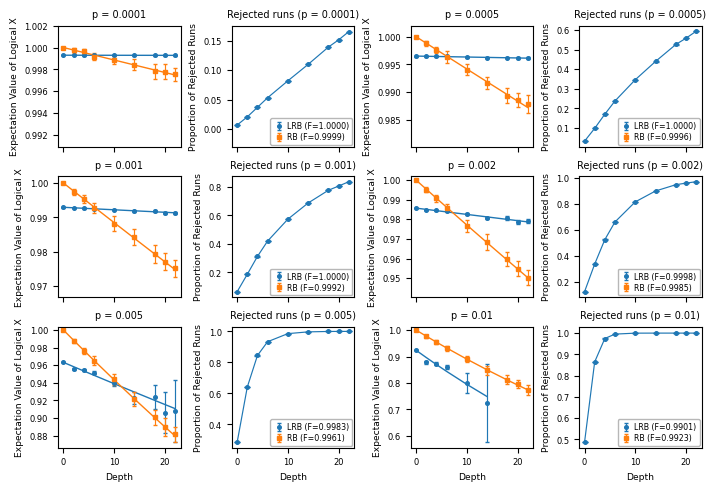

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-38-05-folded_qutrit_layout_b-layout-b-si1000-sdim140/results/plots/unif-3-Summary-Graph-Fit.pdf


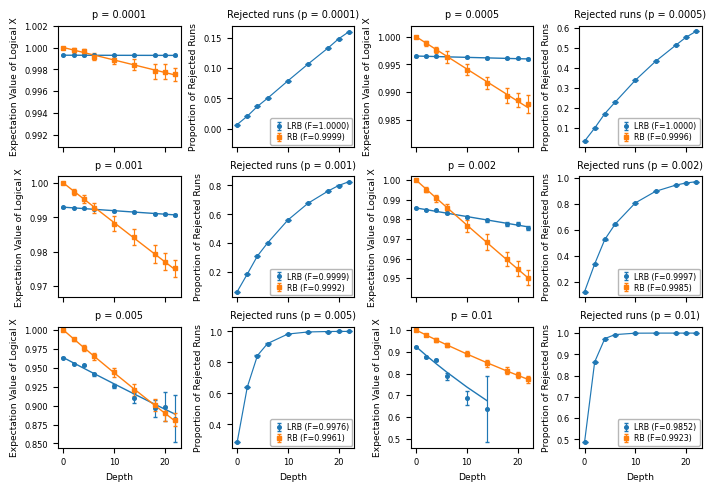

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-38-05-folded_qutrit_layout_b-layout-b-si1000-sdim140/results/plots/unif-4-Summary-Graph-Fit.pdf
=== layoutb_qutrit_sd6


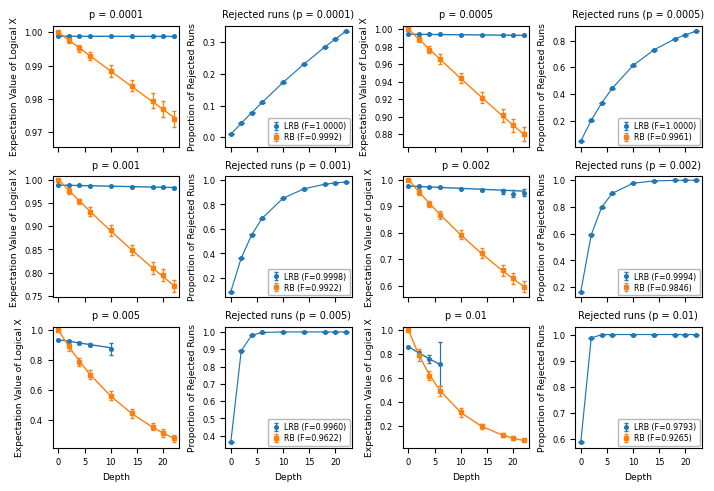

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-39-18-folded_qutrit_layout_b-layout-b-sd6-sdim140/results/plots/unif-1-Summary-Graph-Fit.pdf


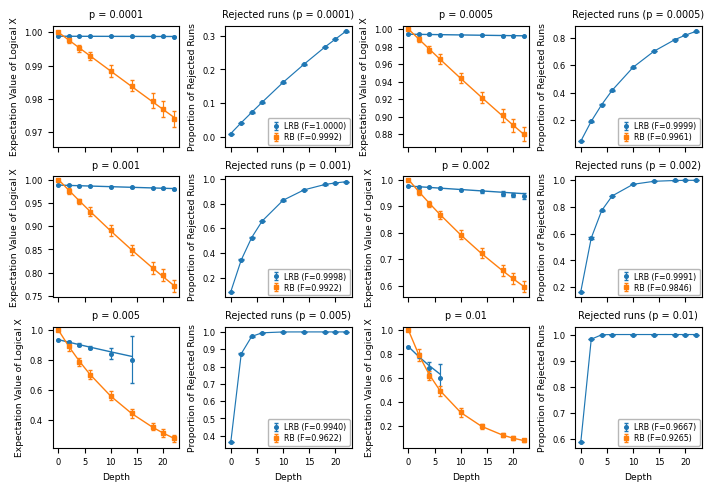

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-39-18-folded_qutrit_layout_b-layout-b-sd6-sdim140/results/plots/unif-2-Summary-Graph-Fit.pdf


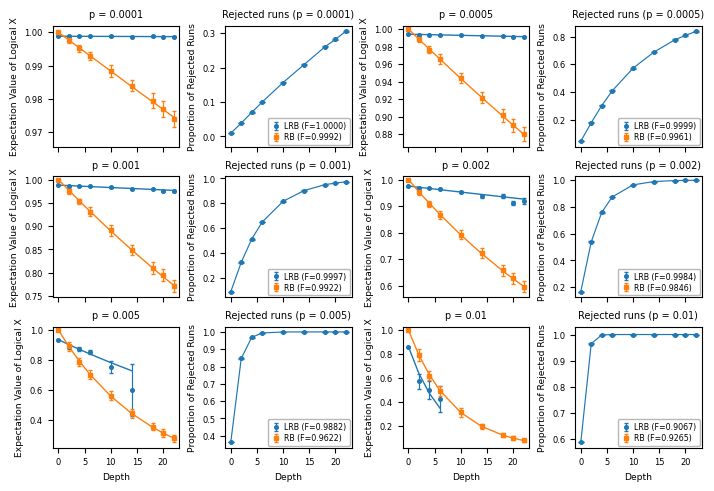

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-39-18-folded_qutrit_layout_b-layout-b-sd6-sdim140/results/plots/unif-3-Summary-Graph-Fit.pdf


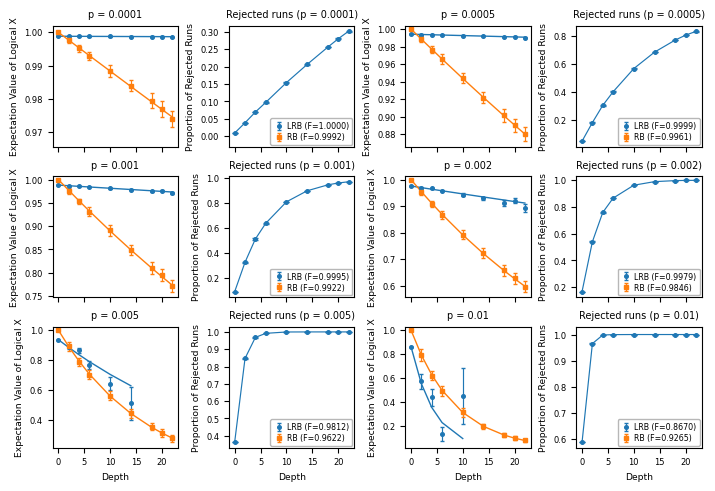

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-39-18-folded_qutrit_layout_b-layout-b-sd6-sdim140/results/plots/unif-4-Summary-Graph-Fit.pdf
=== layoutb_qubit_si1000


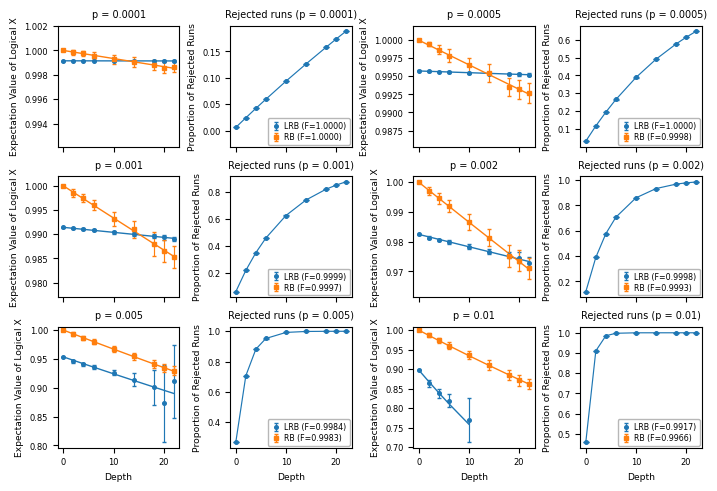

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-40-29-folded_qubit_layout_b-layout-b-si1000-sdim140/results/plots/unif-1-Summary-Graph-Fit.pdf


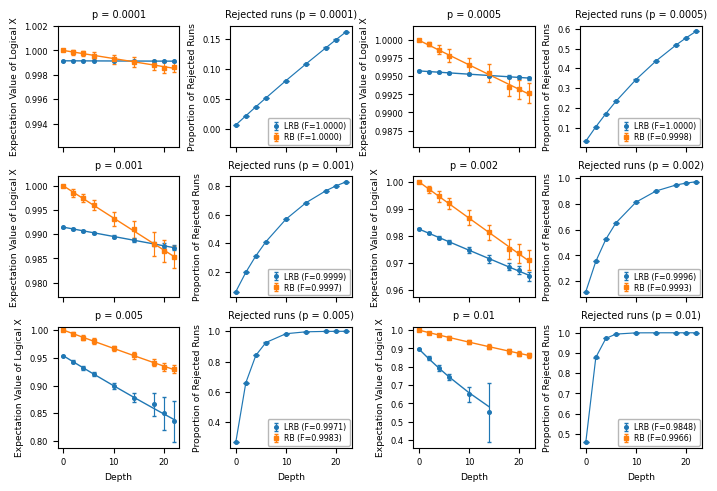

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-40-29-folded_qubit_layout_b-layout-b-si1000-sdim140/results/plots/unif-2-Summary-Graph-Fit.pdf


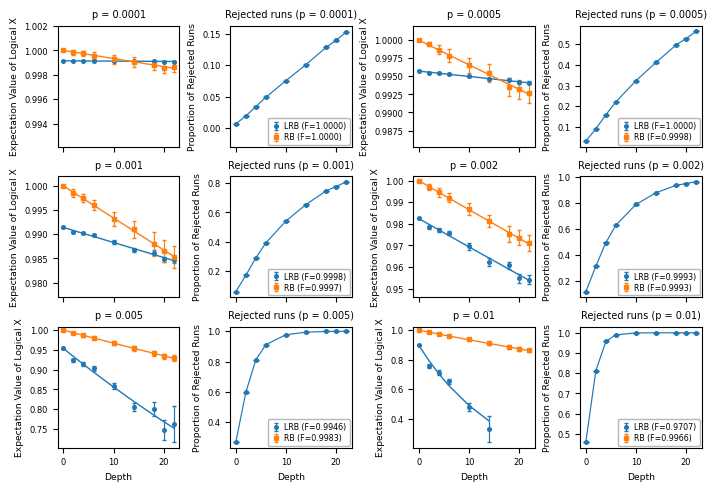

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-40-29-folded_qubit_layout_b-layout-b-si1000-sdim140/results/plots/unif-3-Summary-Graph-Fit.pdf


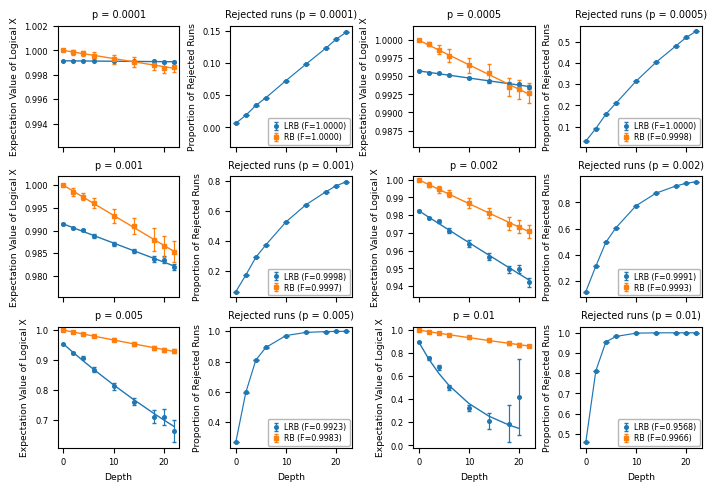

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-40-29-folded_qubit_layout_b-layout-b-si1000-sdim140/results/plots/unif-4-Summary-Graph-Fit.pdf
=== layoutb_qubit_sd6


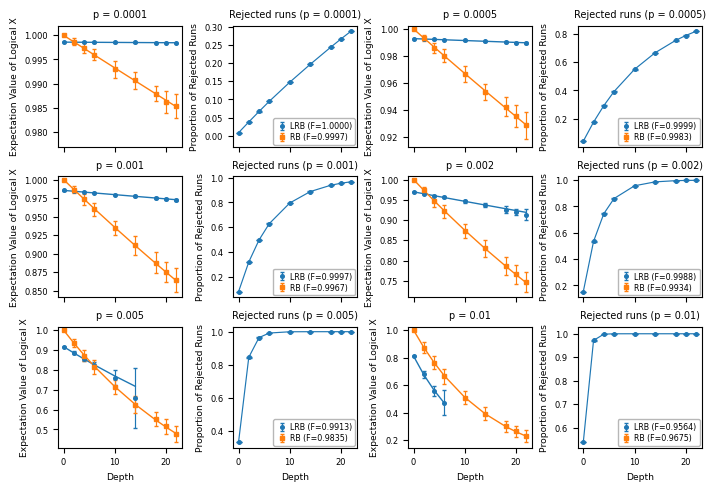

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-41-29-folded_qubit_layout_b-layout-b-sd6-sdim140/results/plots/unif-1-Summary-Graph-Fit.pdf


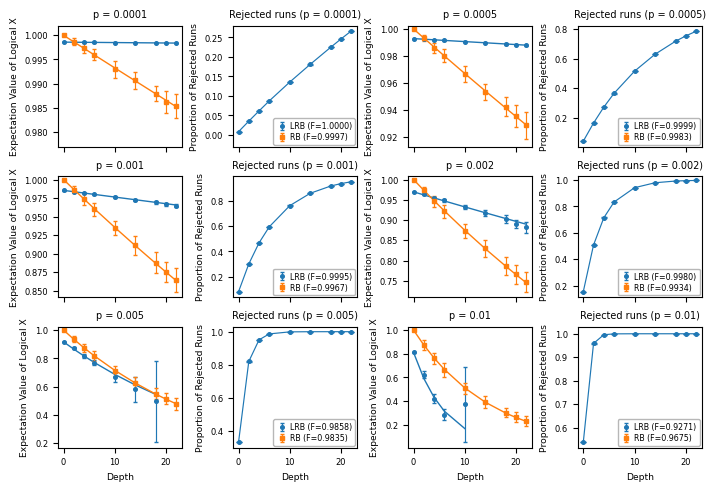

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-41-29-folded_qubit_layout_b-layout-b-sd6-sdim140/results/plots/unif-2-Summary-Graph-Fit.pdf


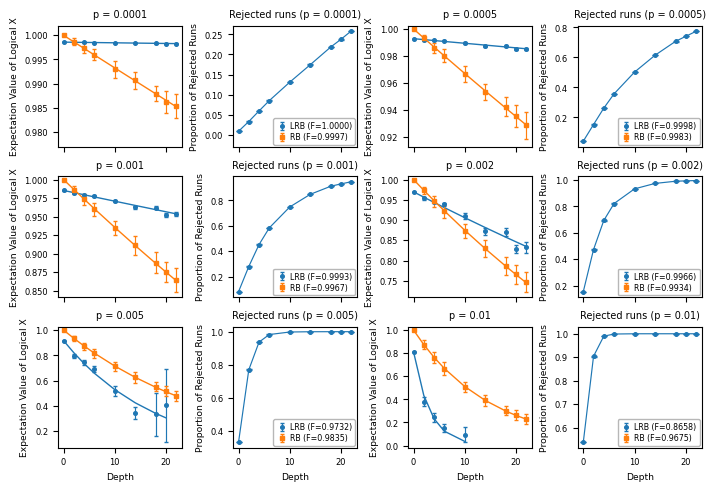

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-41-29-folded_qubit_layout_b-layout-b-sd6-sdim140/results/plots/unif-3-Summary-Graph-Fit.pdf


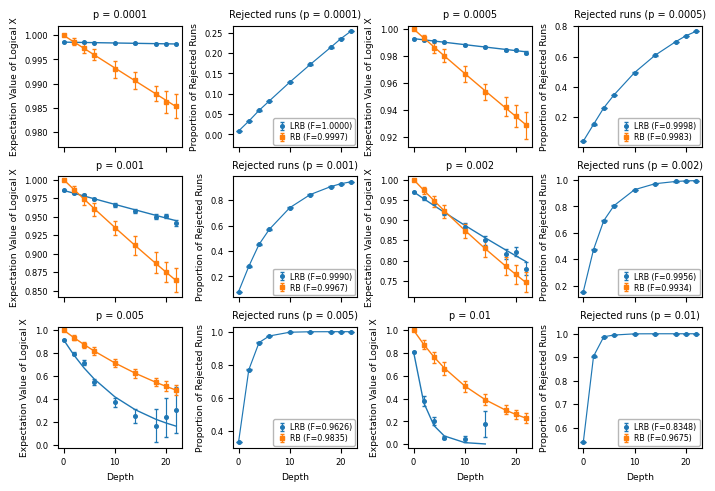

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-41-29-folded_qubit_layout_b-layout-b-sd6-sdim140/results/plots/unif-4-Summary-Graph-Fit.pdf


{'layoutb_qutrit_si1000': ['/pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-38-05-folded_qutrit_layout_b-layout-b-si1000-sdim140/results/plots/unif-1-Summary-Graph-Fit.pdf',
  '/pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-38-05-folded_qutrit_layout_b-layout-b-si1000-sdim140/results/plots/unif-2-Summary-Graph-Fit.pdf',
  '/pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-38-05-folded_qutrit_layout_b-layout-b-si1000-sdim140/results/plots/unif-3-Summary-Graph-Fit.pdf',
  '/pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-38-05-folded_qutrit_layout_b-layout-b-si1000-sdim140/results/plots/unif-4-Summary-Graph-Fit.pdf'],
 'layoutb_qutrit_sd6': ['/pscratch/sd/

In [6]:
unif_plot_min, unif_plot_max = 1, 4
unif_outputs = {}
for label, plotter in plotters.items():
    print(f"=== {label}")
    unif_outputs[label] = plotter.plot_all_unif_checks(
        show=True,
        check_min=unif_plot_min,
        check_max=unif_plot_max,
        paper_config=paper_plot_config,
    )
unif_outputs

### 6. LRB-vs-RB tables and threshold summaries

LRB error rates and physical RB error rates are both placed at the same two-qudit gate error $p$. Uncertainties are bootstrap intervals as before.

=== layoutb_qutrit_si1000


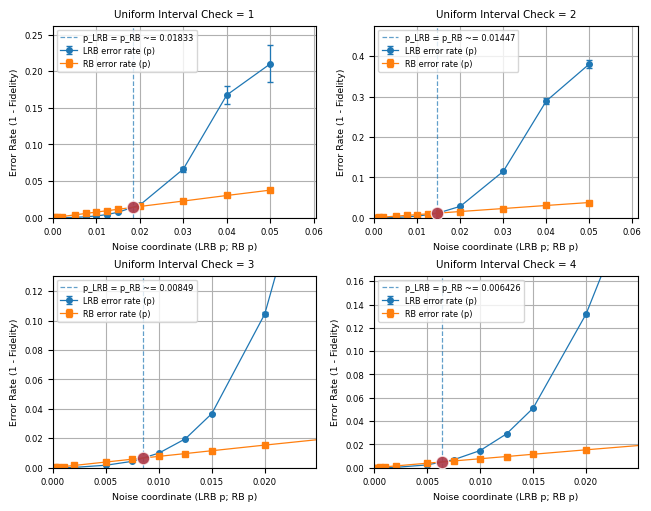

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-38-05-folded_qutrit_layout_b-layout-b-si1000-sdim140/results/plots/unif-threshold-error-vs-p-paper-grid.pdf
[THRESHOLD] Uniform Interval Check = 1: p_LRB = p_RB = 0.0183268 +- 0.000407
[THRESHOLD] Uniform Interval Check = 2: p_LRB = p_RB = 0.01447 +- 0.000183
[THRESHOLD] Uniform Interval Check = 3: p_LRB = p_RB = 0.00848956 +- 4.24e-05
[THRESHOLD] Uniform Interval Check = 4: p_LRB = p_RB = 0.00642599 +- 4.8e-05
[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-38-05-folded_qutrit_layout_b-layout-b-si1000-sdim140/results/plots/unif_thresholds_summary_monotone_trim_zoom_pwindow.csv
[layoutb_qutrit_si1000] error-rate uncertainty table


,check_num,lrb_lambda,rb_p,p_raw,p,lrb_error_rate,lrb_error_rate_ci_low,lrb_error_rate_ci_high,rb_error_rate,rb_error_rate_ci_low,rb_error_rate_ci_high,lrb_unc_minus,lrb_unc_plus,rb_unc_minus,rb_unc_plus
0,1,0.0000,0.0000,0.0000,0.0000,0.000000e+00,0.000000e+00,3.333333e-08,0.000000,0.000000,0.000000,0.000000e+00,3.333333e-08,0.000000,0.000000
1,1,0.0001,0.0001,0.0001,0.0001,1.000000e-07,0.000000e+00,2.680000e-07,0.000076,0.000075,0.000078,1.000000e-07,1.680000e-07,0.000002,0.000002
2,1,0.0002,0.0002,0.0002,0.0002,4.020000e-07,1.675000e-07,6.733333e-07,0.000155,0.000152,0.000157,2.345000e-07,2.713333e-07,0.000002,0.000002
3,1,0.0005,0.0005,0.0005,0.0005,3.640277e-06,3.110066e-06,4.154670e-06,0.000390,0.000386,0.000394,5.302112e-07,5.143925e-07,0.000004,0.000004
4,1,0.0010,0.0010,0.0010,0.0010,1.643827e-05,1.548604e-05,1.740980e-05,0.000773,0.000766,0.000780,9.522250e-07,9.715326e-07,0.000007,0.000007
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
325,22,0.0150,0.0150,0.0150,0.0150,1.716405e-01,1.712601e-01,1.720223e-01,0.011552,0.011483,0.011622,3.804373e-04,3.817600e-04,0.000069,0.000070
326,22,0.0200,0.0200,0.0200,0.0200,2.605595e-01,2.594081e-01,2.617152e-01,0.015373,0.015267,0.015465,1.151339e-03,1.155712e-03,0.000106,0.000092
327,22,0.0300,0.0300,0.0300,0.0300,4.020117e-01,3.992298e-01,4.047479e-01,0.022785,0.022639,0.022920,2.781931e-03,2.736171e-03,0.000145,0.000136
328,22,0.0400,0.0400,0.0400,0.0400,5.037408e-01,4.998847e-01,5.089626e-01,0.030358,0.030160,0.030543,3.856064e-03,5.221824e-03,0.000197,0.000186


[layoutb_qutrit_si1000] pseudo-threshold uncertainty table


,check_num,threshold_lrb_lambda,threshold_lrb_lambda_std_boot,threshold_lrb_lambda_ci_low,threshold_lrb_lambda_ci_high,threshold_unc_minus,threshold_unc_plus
0,1,0.018327,0.000407,0.017983,0.018746,0.000344,0.000419
1,2,0.014470,0.000183,0.014283,0.014649,0.000187,0.000179
2,3,0.008490,0.000042,0.008450,0.008535,0.000039,0.000045
3,4,0.006426,0.000048,0.006382,0.006476,0.000044,0.000050


=== layoutb_qutrit_sd6


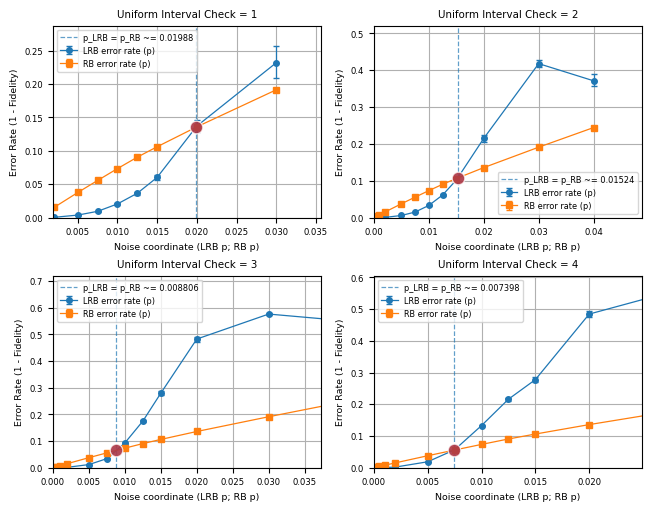

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-39-18-folded_qutrit_layout_b-layout-b-sd6-sdim140/results/plots/unif-threshold-error-vs-p-paper-grid.pdf
[THRESHOLD] Uniform Interval Check = 1: p_LRB = p_RB = 0.0198808 +- 0.0021
[THRESHOLD] Uniform Interval Check = 2: p_LRB = p_RB = 0.0152441 +- 0.000263
[THRESHOLD] Uniform Interval Check = 3: p_LRB = p_RB = 0.00880621 +- 9.57e-05
[THRESHOLD] Uniform Interval Check = 4: p_LRB = p_RB = 0.0073977 +- 0.000121
[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-39-18-folded_qutrit_layout_b-layout-b-sd6-sdim140/results/plots/unif_thresholds_summary_monotone_trim_zoom_pwindow.csv
[layoutb_qutrit_sd6] error-rate uncertainty table


,check_num,lrb_lambda,rb_p,p_raw,p,lrb_error_rate,lrb_error_rate_ci_low,lrb_error_rate_ci_high,rb_error_rate,rb_error_rate_ci_low,rb_error_rate_ci_high,lrb_unc_minus,lrb_unc_plus,rb_unc_minus,rb_unc_plus
0,1,0.0000,0.0000,0.0000,0.0000,0.000000,0.000000,3.333333e-08,0.000000,0.000000,0.000000,0.000000e+00,3.333333e-08,0.000000,0.000000
1,1,0.0001,0.0001,0.0001,0.0001,0.000002,0.000001,1.897775e-06,0.000782,0.000775,0.000788,2.174400e-07,2.577750e-07,0.000007,0.000006
2,1,0.0002,0.0002,0.0002,0.0002,0.000006,0.000006,6.591933e-06,0.001560,0.001550,0.001571,3.933950e-07,4.635900e-07,0.000011,0.000011
3,1,0.0005,0.0005,0.0005,0.0005,0.000039,0.000038,4.031668e-05,0.003861,0.003837,0.003885,1.007035e-06,1.001425e-06,0.000024,0.000024
4,1,0.0010,0.0010,0.0010,0.0010,0.000159,0.000156,1.617079e-04,0.007757,0.007715,0.007798,3.025800e-06,2.853436e-06,0.000042,0.000041
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
325,22,0.0150,0.0150,0.0150,0.0150,0.407735,0.404218,4.116825e-01,0.106197,0.105581,0.106794,3.517397e-03,3.947541e-03,0.000617,0.000597
326,22,0.0200,0.0200,0.0200,0.0200,0.452455,0.448069,4.574106e-01,0.135948,0.134822,0.136938,4.386304e-03,4.955157e-03,0.001126,0.000989
327,22,0.0300,0.0300,0.0300,0.0300,0.574633,0.571109,5.791189e-01,0.191301,0.189361,0.193158,3.523456e-03,4.486336e-03,0.001940,0.001857
328,22,0.0400,0.0400,0.0400,0.0400,0.551103,0.546906,5.555119e-01,0.244582,0.241432,0.247622,4.197397e-03,4.408939e-03,0.003150,0.003040


[layoutb_qutrit_sd6] pseudo-threshold uncertainty table


,check_num,threshold_lrb_lambda,threshold_lrb_lambda_std_boot,threshold_lrb_lambda_ci_low,threshold_lrb_lambda_ci_high,threshold_unc_minus,threshold_unc_plus
0,1,0.019881,0.002098,0.019084,0.021927,0.000797,0.002046
1,2,0.015244,0.000263,0.014968,0.015478,0.000276,0.000233
2,3,0.008806,0.000096,0.008718,0.008906,0.000088,0.000100
3,4,0.007398,0.000121,0.007260,0.007503,0.000138,0.000106


=== layoutb_qubit_si1000


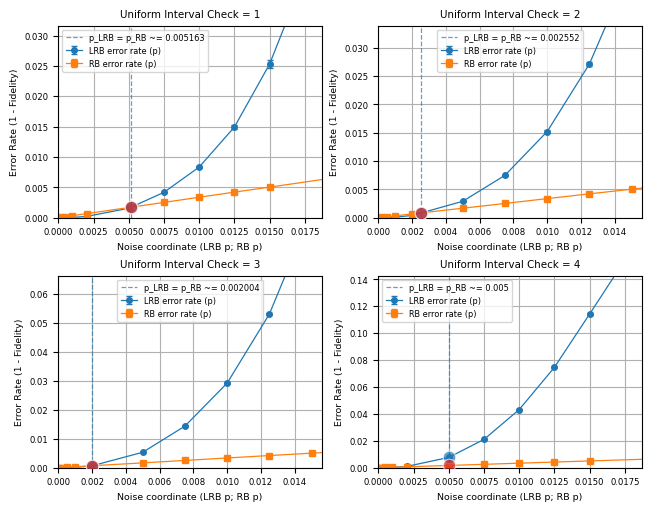

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-40-29-folded_qubit_layout_b-layout-b-si1000-sdim140/results/plots/unif-threshold-error-vs-p-paper-grid.pdf
[THRESHOLD] Uniform Interval Check = 1: p_LRB = p_RB = 0.00516286 +- 4.13e-05
[THRESHOLD] Uniform Interval Check = 2: p_LRB = p_RB = 0.00255196 +- 1.77e-05
[THRESHOLD] Uniform Interval Check = 3: p_LRB = p_RB = 0.00200401 +- 0.00136
[THRESHOLD] Uniform Interval Check = 4: p_LRB = p_RB = 0.005 +- 0
[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-40-29-folded_qubit_layout_b-layout-b-si1000-sdim140/results/plots/unif_thresholds_summary_monotone_trim_zoom_pwindow.csv
[layoutb_qubit_si1000] error-rate uncertainty table


,check_num,lrb_lambda,rb_p,p_raw,p,lrb_error_rate,lrb_error_rate_ci_low,lrb_error_rate_ci_high,rb_error_rate,rb_error_rate_ci_low,rb_error_rate_ci_high,lrb_unc_minus,lrb_unc_plus,rb_unc_minus,rb_unc_plus
0,1,0.0000,0.0000,0.0000,0.0000,0.000000e+00,0.000000e+00,2.500000e-08,0.000000,0.000000,0.000000,0.000000e+00,2.500000e-08,0.000000e+00,0.000000e+00
1,1,0.0001,0.0001,0.0001,0.0001,2.261250e-07,7.500000e-08,4.040000e-07,0.000033,0.000032,0.000034,1.511250e-07,1.778750e-07,9.659683e-07,9.476823e-07
2,1,0.0002,0.0002,0.0002,0.0002,2.064270e-06,1.820306e-06,2.336751e-06,0.000067,0.000065,0.000068,2.439637e-07,2.724806e-07,1.491035e-06,1.447644e-06
3,1,0.0005,0.0005,0.0005,0.0005,1.191409e-05,1.134829e-05,1.244222e-05,0.000170,0.000168,0.000173,5.658000e-07,5.281312e-07,2.871465e-06,2.862562e-06
4,1,0.0010,0.0010,0.0010,0.0010,5.215329e-05,5.102636e-05,5.315607e-05,0.000333,0.000329,0.000338,1.126932e-06,1.002771e-06,4.644675e-06,4.703586e-06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
325,22,0.0150,0.0150,0.0150,0.0150,1.822740e-01,1.816208e-01,1.829483e-01,0.005032,0.004987,0.005079,6.531840e-04,6.743200e-04,4.580068e-05,4.703050e-05
326,22,0.0200,0.0200,0.0200,0.0200,2.443900e-01,2.433151e-01,2.454534e-01,0.006717,0.006647,0.006779,1.074848e-03,1.063360e-03,7.055160e-05,6.178032e-05
327,22,0.0300,0.0300,0.0300,0.0300,3.405396e-01,3.383257e-01,3.426660e-01,0.010015,0.009924,0.010102,2.213872e-03,2.126368e-03,9.168000e-05,8.675520e-05
328,22,0.0400,0.0400,0.0400,0.0400,4.051060e-01,4.016617e-01,4.088583e-01,0.013275,0.013156,0.013390,3.444336e-03,3.752352e-03,1.194160e-04,1.148229e-04


[layoutb_qubit_si1000] pseudo-threshold uncertainty table


,check_num,threshold_lrb_lambda,threshold_lrb_lambda_std_boot,threshold_lrb_lambda_ci_low,threshold_lrb_lambda_ci_high,threshold_unc_minus,threshold_unc_plus
0,1,0.005163,0.000041,0.005122,0.005203,4.095124e-05,0.000040
1,2,0.002552,0.000018,0.002535,0.002570,1.654456e-05,0.000018
2,3,0.002004,0.001360,0.002003,0.005000,6.119448e-07,0.002996
3,4,0.005000,0.000000,0.005000,0.005000,0.000000e+00,0.000000


=== layoutb_qubit_sd6


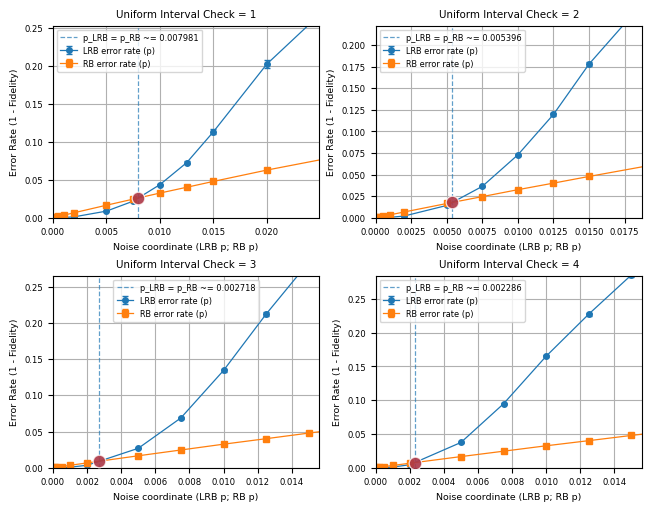

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-41-29-folded_qubit_layout_b-layout-b-sd6-sdim140/results/plots/unif-threshold-error-vs-p-paper-grid.pdf
[THRESHOLD] Uniform Interval Check = 1: p_LRB = p_RB = 0.00798145 +- 7.69e-05
[THRESHOLD] Uniform Interval Check = 2: p_LRB = p_RB = 0.0053964 +- 3.77e-05
[THRESHOLD] Uniform Interval Check = 3: p_LRB = p_RB = 0.00271811 +- 2.06e-05
[THRESHOLD] Uniform Interval Check = 4: p_LRB = p_RB = 0.00228621 +- 9.43e-06
[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-41-29-folded_qubit_layout_b-layout-b-sd6-sdim140/results/plots/unif_thresholds_summary_monotone_trim_zoom_pwindow.csv
[layoutb_qubit_sd6] error-rate uncertainty table


,check_num,lrb_lambda,rb_p,p_raw,p,lrb_error_rate,lrb_error_rate_ci_low,lrb_error_rate_ci_high,rb_error_rate,rb_error_rate_ci_low,rb_error_rate_ci_high,lrb_unc_minus,lrb_unc_plus,rb_unc_minus,rb_unc_plus
0,1,0.0000,0.0000,0.0000,0.0000,0.000000,0.000000,2.500000e-08,0.000000,0.000000,0.000000,0.000000e+00,2.500000e-08,0.000000,0.000000
1,1,0.0001,0.0001,0.0001,0.0001,0.000003,0.000003,3.093631e-06,0.000339,0.000335,0.000344,2.246175e-07,2.308887e-07,0.000004,0.000004
2,1,0.0002,0.0002,0.0002,0.0002,0.000011,0.000010,1.099879e-05,0.000664,0.000656,0.000672,3.325200e-07,3.846675e-07,0.000008,0.000008
3,1,0.0005,0.0005,0.0005,0.0005,0.000071,0.000070,7.234539e-05,0.001682,0.001663,0.001699,1.157100e-06,1.125889e-06,0.000018,0.000018
4,1,0.0010,0.0010,0.0010,0.0010,0.000293,0.000290,2.955403e-04,0.003330,0.003297,0.003363,3.166072e-06,2.862397e-06,0.000034,0.000033
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
325,22,0.0150,0.0150,0.0150,0.0150,0.321445,0.319116,3.239083e-01,0.047808,0.047408,0.048213,2.328928e-03,2.463056e-03,0.000399,0.000406
326,22,0.0200,0.0200,0.0200,0.0200,0.376886,0.373624,3.802078e-01,0.062741,0.062111,0.063288,3.261312e-03,3.322160e-03,0.000630,0.000547
327,22,0.0300,0.0300,0.0300,0.0300,0.447828,0.444785,4.509847e-01,0.089844,0.088866,0.090728,3.043440e-03,3.156351e-03,0.000978,0.000884
328,22,0.0400,0.0400,0.0400,0.0400,0.431906,0.428367,4.357435e-01,0.114676,0.113217,0.116139,3.539040e-03,3.837536e-03,0.001459,0.001463


[layoutb_qubit_sd6] pseudo-threshold uncertainty table


,check_num,threshold_lrb_lambda,threshold_lrb_lambda_std_boot,threshold_lrb_lambda_ci_low,threshold_lrb_lambda_ci_high,threshold_unc_minus,threshold_unc_plus
0,1,0.007981,0.000077,0.007904,0.008055,0.000077,0.000074
1,2,0.005396,0.000038,0.005359,0.005434,0.000037,0.000038
2,3,0.002718,0.000021,0.002698,0.002739,0.000020,0.000021
3,4,0.002286,0.000009,0.002277,0.002296,0.000010,0.000010


In [7]:
point_ci_columns = [
    "lrb_error_rate_std_boot",
    "lrb_error_rate_ci_low",
    "lrb_error_rate_ci_high",
    "rb_error_rate_std_boot",
    "rb_error_rate_ci_low",
    "rb_error_rate_ci_high",
]
force_rebuild_uncertainty_table = False


def table_has_point_uncertainty(path: Path) -> bool:
    if not path.exists():
        return False
    columns = pd.read_csv(path, nrows=0).columns
    return all(col in columns for col in point_ci_columns)


table_csvs, summary_csvs, uncertainty_tables, pseudo_threshold_tables = {}, {}, {}, {}
for label, plotter in plotters.items():
    print(f"=== {label}")
    table_csv_path = Path(plotter.out_dir) / "unif_lrb_vs_rb_table_all_mixed_fits.csv"
    if force_rebuild_uncertainty_table or not table_has_point_uncertainty(table_csv_path):
        table_csvs[label] = plotter.build_unif_lrb_vs_rb_table_mixed_fits(
            write_per_check_tables=True,
            check_min=unif_check_min,
            check_max=unif_check_max,
            bootstrap_reps=threshold_config.bootstrap_reps_error,
            bootstrap_ci_level=threshold_config.bootstrap_ci_level,
            bootstrap_use_sem=threshold_config.bootstrap_use_sem,
            bootstrap_seed=threshold_config.bootstrap_seed,
        )
    else:
        table_csvs[label] = str(table_csv_path)
    summary_csvs[label] = plotter.plot_all_unif_threshold_graphs(
        threshold_config=threshold_config,
        table_csv_path=table_csvs[label],
        show=True,
        check_min=unif_check_min,
        check_max=4,
    )
    uncertainty_tables[label] = show_error_rate_uncertainty_table(table_csvs[label], label=label)
    pseudo_threshold_tables[label] = show_pseudo_threshold_uncertainty_table(
        summary_csvs[label],
        label=label,
        check_min=unif_check_min,
        check_max=unif_check_max,
    )

### 7. Pseudo-threshold trend vs interval check

The focused `1..4` pseudo-threshold trend for every run.

[PSEUDO] Uniform Interval Check = 1: p_LRB = p_RB = 0.0183268 +- 0.000407
[PSEUDO] Uniform Interval Check = 2: p_LRB = p_RB = 0.01447 +- 0.000183
[PSEUDO] Uniform Interval Check = 3: p_LRB = p_RB = 0.00848956 +- 4.24e-05
[PSEUDO] Uniform Interval Check = 4: p_LRB = p_RB = 0.00642599 +- 4.8e-05
[FIT] fit disabled by do_fit=False.


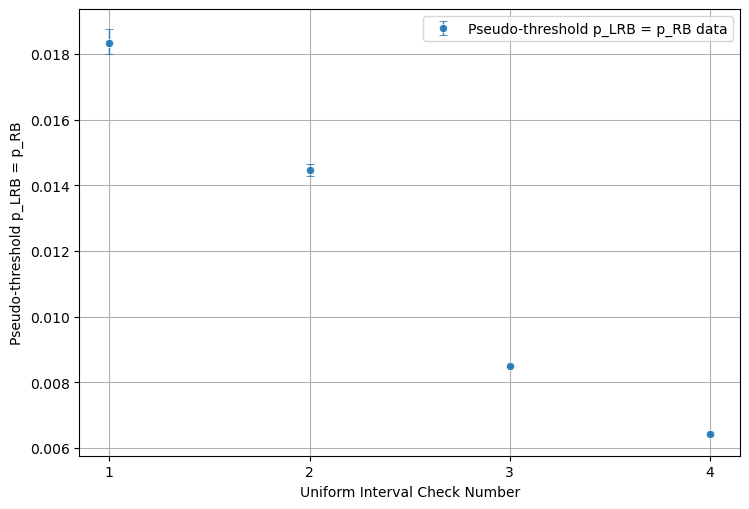

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-38-05-folded_qutrit_layout_b-layout-b-si1000-sdim140/results/plots/unif-1-to-4-pseudo-threshold-vs-interval-check-fit.pdf
[PSEUDO] Uniform Interval Check = 1: p_LRB = p_RB = 0.0198808 +- 0.0021
[PSEUDO] Uniform Interval Check = 2: p_LRB = p_RB = 0.0152441 +- 0.000263
[PSEUDO] Uniform Interval Check = 3: p_LRB = p_RB = 0.00880621 +- 9.57e-05
[PSEUDO] Uniform Interval Check = 4: p_LRB = p_RB = 0.0073977 +- 0.000121
[FIT] fit disabled by do_fit=False.


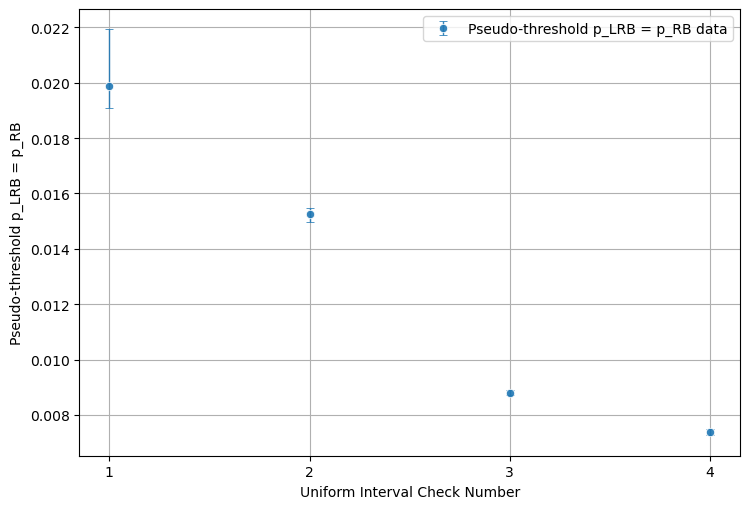

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-39-18-folded_qutrit_layout_b-layout-b-sd6-sdim140/results/plots/unif-1-to-4-pseudo-threshold-vs-interval-check-fit.pdf
[PSEUDO] Uniform Interval Check = 1: p_LRB = p_RB = 0.00516286 +- 4.13e-05
[PSEUDO] Uniform Interval Check = 2: p_LRB = p_RB = 0.00255196 +- 1.77e-05
[PSEUDO] Uniform Interval Check = 3: p_LRB = p_RB = 0.00200401 +- 0.00136
[PSEUDO] Uniform Interval Check = 4: p_LRB = p_RB = 0.005 +- 0
[FIT] fit disabled by do_fit=False.


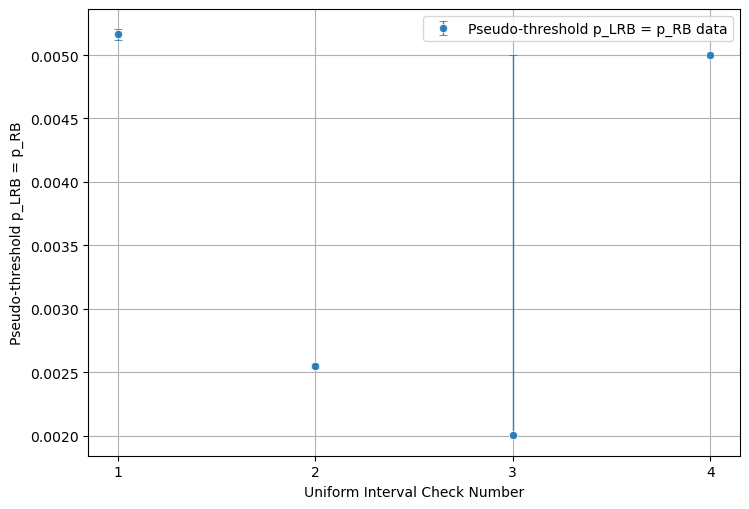

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-40-29-folded_qubit_layout_b-layout-b-si1000-sdim140/results/plots/unif-1-to-4-pseudo-threshold-vs-interval-check-fit.pdf
[PSEUDO] Uniform Interval Check = 1: p_LRB = p_RB = 0.00798145 +- 7.69e-05
[PSEUDO] Uniform Interval Check = 2: p_LRB = p_RB = 0.0053964 +- 3.77e-05
[PSEUDO] Uniform Interval Check = 3: p_LRB = p_RB = 0.00271811 +- 2.06e-05
[PSEUDO] Uniform Interval Check = 4: p_LRB = p_RB = 0.00228621 +- 9.43e-06
[FIT] fit disabled by do_fit=False.


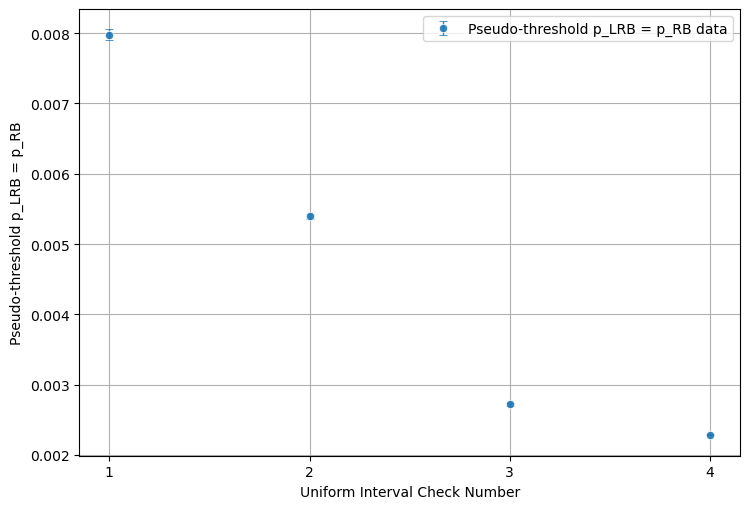

[OK] wrote /pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-41-29-folded_qubit_layout_b-layout-b-sd6-sdim140/results/plots/unif-1-to-4-pseudo-threshold-vs-interval-check-fit.pdf


{'layoutb_qutrit_si1000': '/pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-38-05-folded_qutrit_layout_b-layout-b-si1000-sdim140/results/plots/unif-1-to-4-pseudo-threshold-vs-interval-check-fit.pdf',
 'layoutb_qutrit_sd6': '/pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-39-18-folded_qutrit_layout_b-layout-b-sd6-sdim140/results/plots/unif-1-to-4-pseudo-threshold-vs-interval-check-fit.pdf',
 'layoutb_qubit_si1000': '/pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-40-29-folded_qubit_layout_b-layout-b-si1000-sdim140/results/plots/unif-1-to-4-pseudo-threshold-vs-interval-check-fit.pdf',
 'layoutb_qubit_sd6': '/pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/Run-2026-11-17-14-

In [8]:
pseudo_pdfs = {}
for label, plotter in plotters.items():
    pseudo_pdfs[label] = plotter.plot_unif_pseudo_thresholds_vs_interval_check(
        check_min=unif_check_min,
        check_max=4,
        do_fit=pseudo_do_fit,
        fit_model=pseudo_fit_model,
        fit_degree=pseudo_fit_degree,
        paper_mode=paper_plot_config.enabled,
        show=True,
    )
pseudo_pdfs

### 8. Comparison with the one-ancilla and conventional-site layouts

Logical error per Clifford with a check after every Clifford (uniform interval 1) versus the two-qudit gate error $p$, for the one-ancilla runs, the conventional-site two-ancilla runs (the version the two-ancilla layout replaces in the paper) and the two-ancilla-layout runs, against physical RB under each noise model. The existing runs' tables are read as saved. Points without a valid fit are omitted.


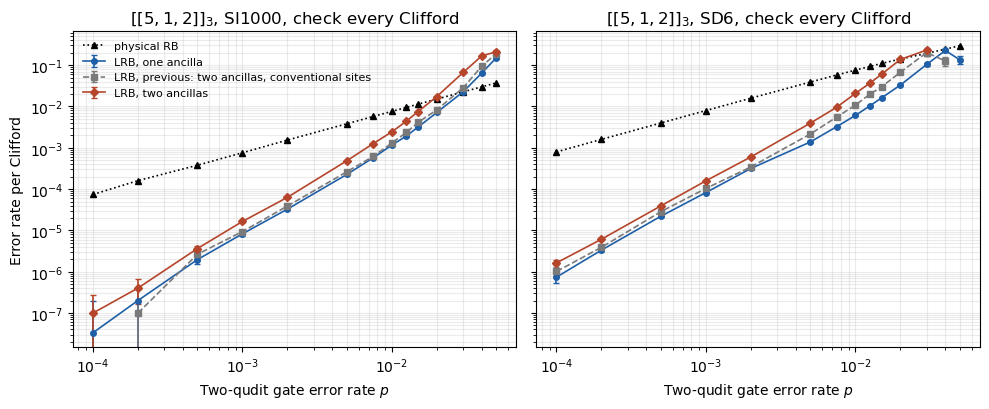

/pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/comparisons/sdim140-layout-b/lrb-vs-rb-unif-1-qutrit-layouts.pdf


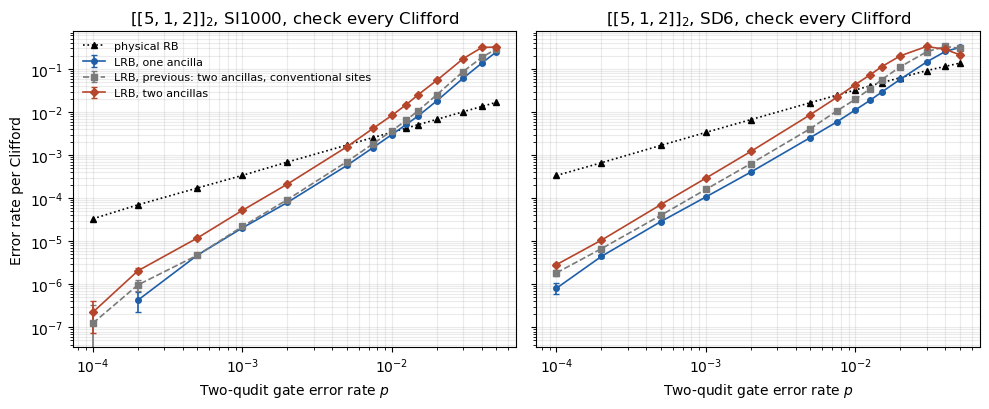

/pscratch/sd/s/sohan100/worktrees/LRB-Simulations-sdim-2bc490701489f8e7/a1-square-layout/LRB-experiment-data-slurm/comparisons/sdim140-layout-b/lrb-vs-rb-unif-1-qubit-layouts.pdf


In [9]:
import matplotlib.pyplot as plt
import numpy as np

comparison_dir = RUNS_ROOT / "comparisons" / "sdim140-layout-b"
comparison_dir.mkdir(parents=True, exist_ok=True)
comparison_check = 1
TABLE_NAME = "unif_lrb_vs_rb_table_all_mixed_fits.csv"
EXISTING_RUNS = {
    ("qutrit", "si1000", "one ancilla"): "Run-2026-10-28-10-23-30-folded_qutrit-single-ancilla-si1000-sdim140",
    ("qutrit", "sd6", "one ancilla"): "Run-2026-10-28-10-24-46-folded_qutrit-single-ancilla-sd6-sdim140",
    ("qutrit", "si1000", "previous: two ancillas, conventional sites"): "Run-2026-11-01-09-22-32-folded_qutrit_conv_sites-conv-sites-si1000-sdim140",
    ("qutrit", "sd6", "previous: two ancillas, conventional sites"): "Run-2026-11-01-09-24-10-folded_qutrit_conv_sites-conv-sites-sd6-sdim140",
    ("qubit", "si1000", "one ancilla"): "Run-2026-10-31-10-12-55-folded_qubit-single-ancilla-si1000-sdim140",
    ("qubit", "sd6", "one ancilla"): "Run-2026-10-31-10-13-03-folded_qubit-single-ancilla-sd6-sdim140",
    ("qubit", "si1000", "previous: two ancillas, conventional sites"): "Run-2026-11-01-09-26-44-folded_qubit_conv_sites-conv-sites-si1000-sdim140",
    ("qubit", "sd6", "previous: two ancillas, conventional sites"): "Run-2026-11-01-09-28-00-folded_qubit_conv_sites-conv-sites-sd6-sdim140",
}
tables = {key: RUNS_ROOT / run / "results" / "plots" / TABLE_NAME for key, run in EXISTING_RUNS.items()}
for label, table_csv in table_csvs.items():
    _, code, noise = label.split("_")
    tables[(code, noise, "two ancillas")] = Path(table_csv)
styles = {
    "one ancilla": dict(color="#1f5fa8", marker="o", linestyle="-"),
    "previous: two ancillas, conventional sites": dict(color="#7a7a7a", marker="s", linestyle="--"),
    "two ancillas": dict(color="#b5452b", marker="D", linestyle="-"),
}
rows = []
for code, title in (("qutrit", r"$[[5,1,2]]_3$"), ("qubit", r"$[[5,1,2]]_2$")):
    fig, axes = plt.subplots(1, 2, figsize=(10.0, 4.2), sharey=True)
    for ax, noise in zip(axes, ("si1000", "sd6")):
        for layout, style in styles.items():
            frame = pd.read_csv(tables[(code, noise, layout)])
            frame = frame[(frame["check_num"] == comparison_check) & (frame["p"] > 0)].sort_values("p")
            lrb = frame[np.isfinite(frame["lrb_error_rate"]) & (frame["lrb_error_rate"] > 0)]
            yerr = np.vstack([
                lrb["lrb_error_rate"] - lrb["lrb_error_rate_ci_low"],
                lrb["lrb_error_rate_ci_high"] - lrb["lrb_error_rate"],
            ]).clip(min=0)
            ax.errorbar(lrb["p"], lrb["lrb_error_rate"], yerr=yerr, markersize=4, capsize=2,
                        linewidth=1.2, label=f"LRB, {layout}", **style)
            rows.append(frame.assign(code=code, noise=noise, layout=layout))
        frame = pd.read_csv(tables[(code, noise, "one ancilla")])
        frame = frame[(frame["check_num"] == comparison_check) & (frame["p"] > 0)].sort_values("p")
        rb = frame[np.isfinite(frame["rb_error_rate"]) & (frame["rb_error_rate"] > 0)]
        ax.plot(rb["p"], rb["rb_error_rate"], color="black", linestyle=":", marker="^", markersize=4,
                linewidth=1.2, label="physical RB")
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlabel(fit_config.p_axis_label)
        ax.set_title(f"{title}, {noise.upper()}, check every Clifford")
        ax.grid(True, which="both", alpha=0.25)
    axes[0].set_ylabel("Error rate per Clifford")
    axes[0].legend(fontsize=8, frameon=False)
    fig.tight_layout()
    comparison_pdf = comparison_dir / f"lrb-vs-rb-unif-{comparison_check}-{code}-layouts.pdf"
    fig.savefig(comparison_pdf)
    fig.savefig(comparison_pdf.with_suffix(".png"), dpi=160)
    plt.show()
    print(comparison_pdf)
comparison_table = pd.concat(rows, ignore_index=True)[
    ["code", "noise", "layout", "p", "lrb_error_rate", "lrb_error_rate_ci_low", "lrb_error_rate_ci_high",
     "rb_error_rate", "rb_error_rate_ci_low", "rb_error_rate_ci_high"]
]
comparison_table.to_csv(comparison_dir / f"lrb-vs-rb-unif-{comparison_check}-layouts.csv", index=False)


## 9. Reading guide

Per-run PDFs and tables are under each run's `results/plots/`; the layout comparison is under `LRB-experiment-data-slurm/comparisons/sdim140-layout-b/`. Pseudo-thresholds with the high-p extensions (qutrit) or near-threshold refinements (qubit) merged in come from `scripts/merge_highp_threshold_extension.py layout-b-sd6 layout-b-si1000` and `... qubit-layout-b-sd6 qubit-layout-b-si1000`, written to `comparisons/pseudo-thresholds-layout-b-current.md` and `comparisons/pseudo-thresholds-qubit-layout-b-current.md`. GIF animations are not made for these runs. In every figure the horizontal axis is the two-qudit gate depolarizing probability $p$; SI1000 sets one-qudit gates to $p/10$, measurement flips to $5p$, reset flips and resonator idles to $2p$, and idles to $p/10$, and SD6 sets every operation to $p$.
